# HW2: Multiple Linear Regression (WHO Life Expectancy)
## 遵循 CRISP-DM 流程之多元線性迴歸與特徵選擇實作

- **課程名稱**：人工智慧與物聯網 (AIoT)
- **實作主題**：WHO 預期壽命 (Life Expectancy) 預測與特徵選擇分析
- **資料集來源**：[Kaggle: Life Expectancy (WHO)](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who)
- **特徵數量**：20 個候選預測特徵（符合作業要求之 15~39 個特徵）
- **核心方法**：多元線性迴歸 (Multiple Linear Regression)、正則化線性迴歸 (Ridge, Lasso, ElasticNet)、四種特徵選擇方法 (SelectKBest, RFE, LassoCV, VIF Filter)


## 1. Business Understanding (商業與研究理解)
- **研究背景**：世界衛生組織 (WHO) 全球衛生觀察站 (GHO) 彙整 2000-2015 年全球各國之衛生、經濟、免疫接種與人口統計數據。
- **目標問題**：建立多元線性迴歸模型，精準預測各國之預期壽命 (Life expectancy)，並量化各健康與政策因素之影響力。
- **商業/政策價值**：協助國際衛生組織與各國政府將有限資源優先投入最具效益之關鍵指標（如教育、疫苗覆蓋率、降低死亡率）。


In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import DataLoader
from src.preprocessor import DataPreprocessor
from src.feature_selection import FeatureSelector
from src.models import RegressionTrainer
from src.evaluation import ModelEvaluator
from src.visualization import Visualizer
from src.deployment import ModelDeployer, LifeExpectancyPredictor

%matplotlib inline
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False


## 2. Data Understanding (資料理解與探索性分析 EDA)
載入原始資料集，檢視資料維度、缺失值狀況、目標變數分佈以及特徵相關係數。


In [2]:
loader = DataLoader()
raw_df = loader.load_data()
print('資料維度 (Rows, Columns):', raw_df.shape)
raw_df.head()


資料維度 (Rows, Columns): (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
# 缺失值統計
missing_df = loader.get_missing_values()
print('缺失值欄位統計 (前 10 名)：')
missing_df.head(10)


缺失值欄位統計 (前 10 名)：


,Missing Count,Percentage (%)
Population,652,22.19
Hepatitis B,553,18.82
GDP,448,15.25
Total expenditure,226,7.69
Alcohol,194,6.60
Income composition of resources,167,5.68
Schooling,163,5.55
thinness 5-9 years,34,1.16
thinness 1-19 years,34,1.16
BMI,34,1.16


In [4]:
# 特徵與目標變數 (Life expectancy) 相關係數排序
target_corr = loader.get_feature_correlations()
pd.DataFrame({'Pearson Correlation with Life Expectancy': target_corr})


,Pearson Correlation with Life Expectancy
Life expectancy,1.000000
Schooling,0.751975
Income composition of resources,0.724776
BMI,0.567694
Diphtheria,0.479495
Polio,0.465556
GDP,0.461455
Alcohol,0.404877
percentage expenditure,0.381864
Hepatitis B,0.256762


### 資料視覺化 (EDA)
顯示目標分佈圖、相關性熱力圖與關鍵特徵分佈。


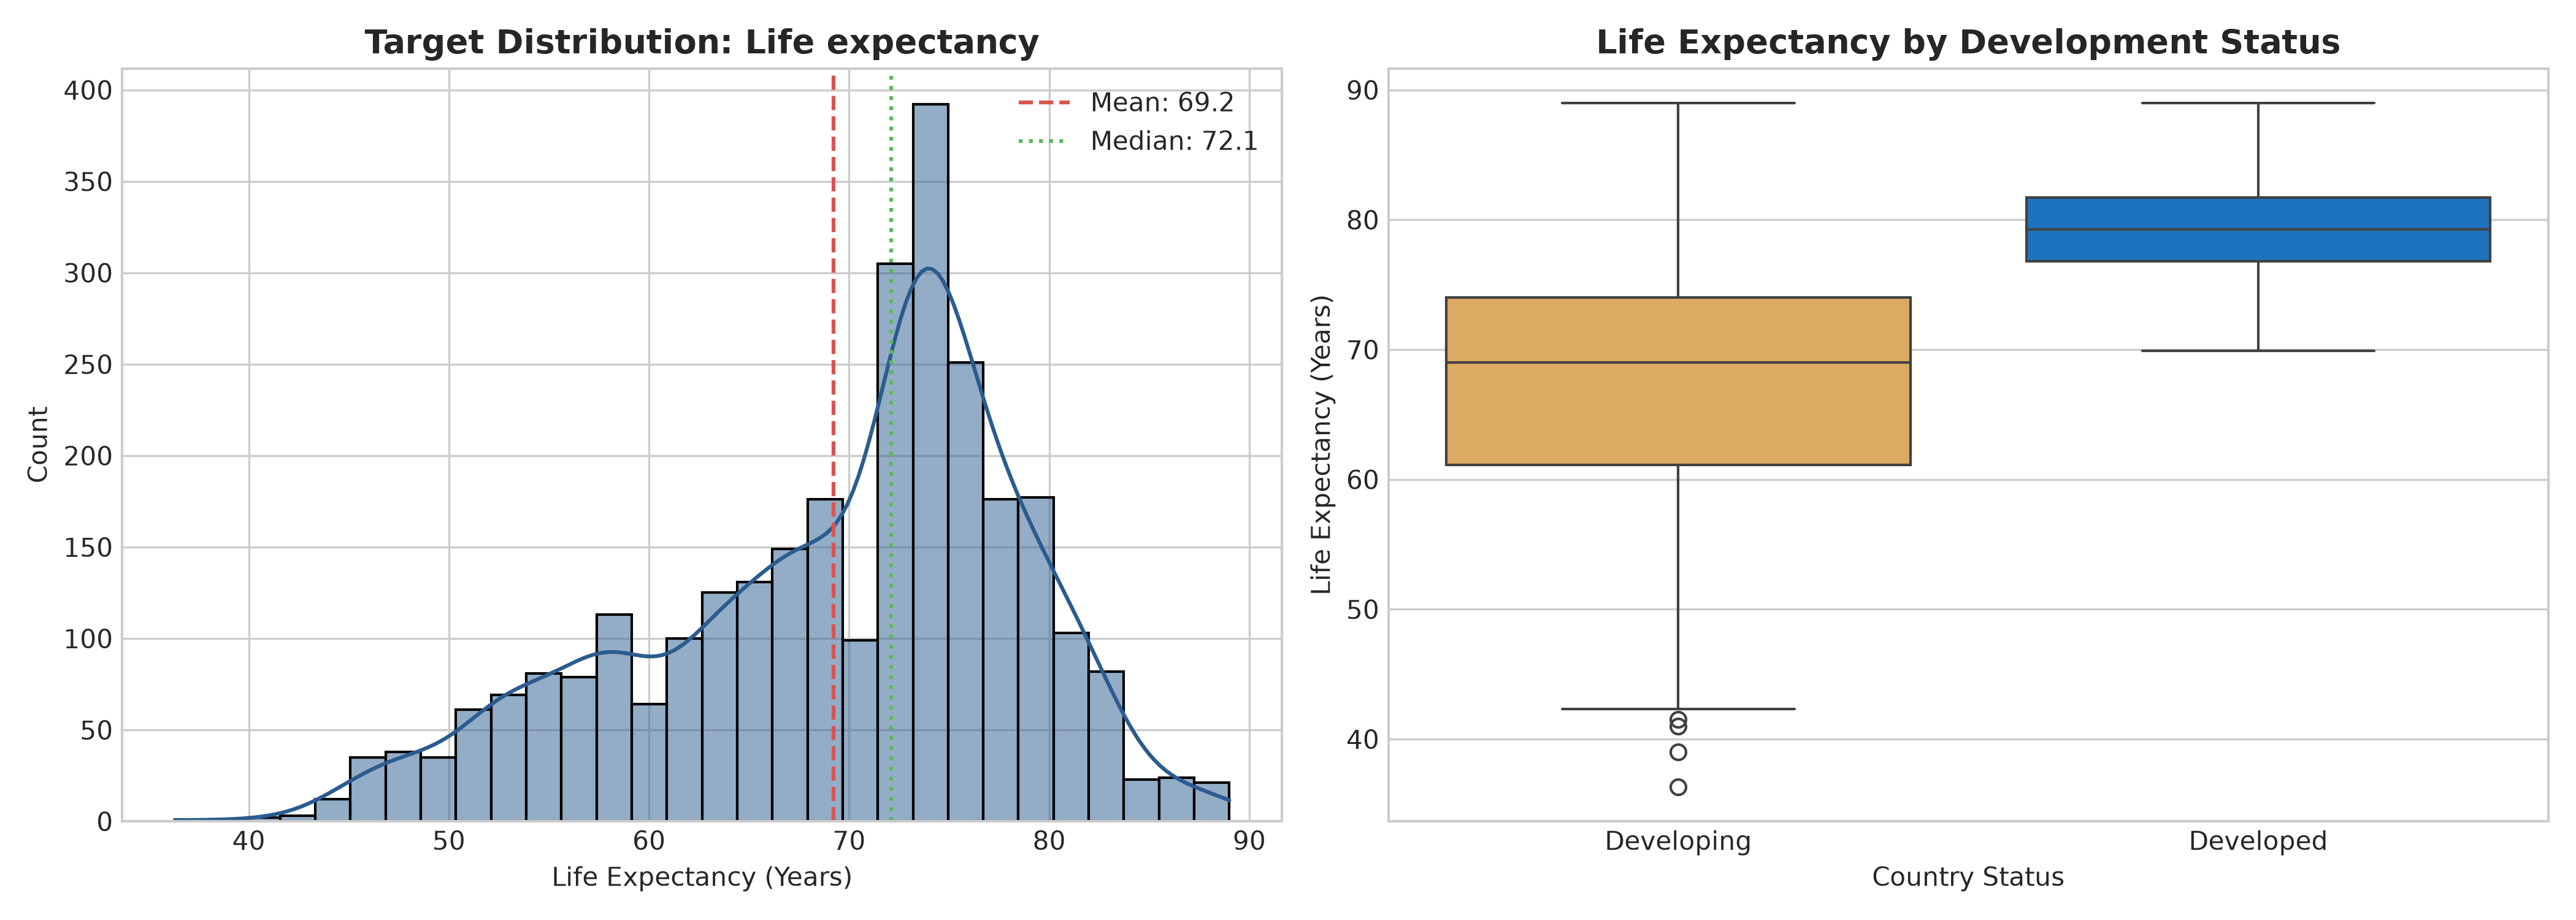

In [5]:
viz = Visualizer(output_dir='figures')
viz.plot_target_distribution(raw_df);
from IPython.display import Image, display
display(Image('figures/01_target_distribution.png'))


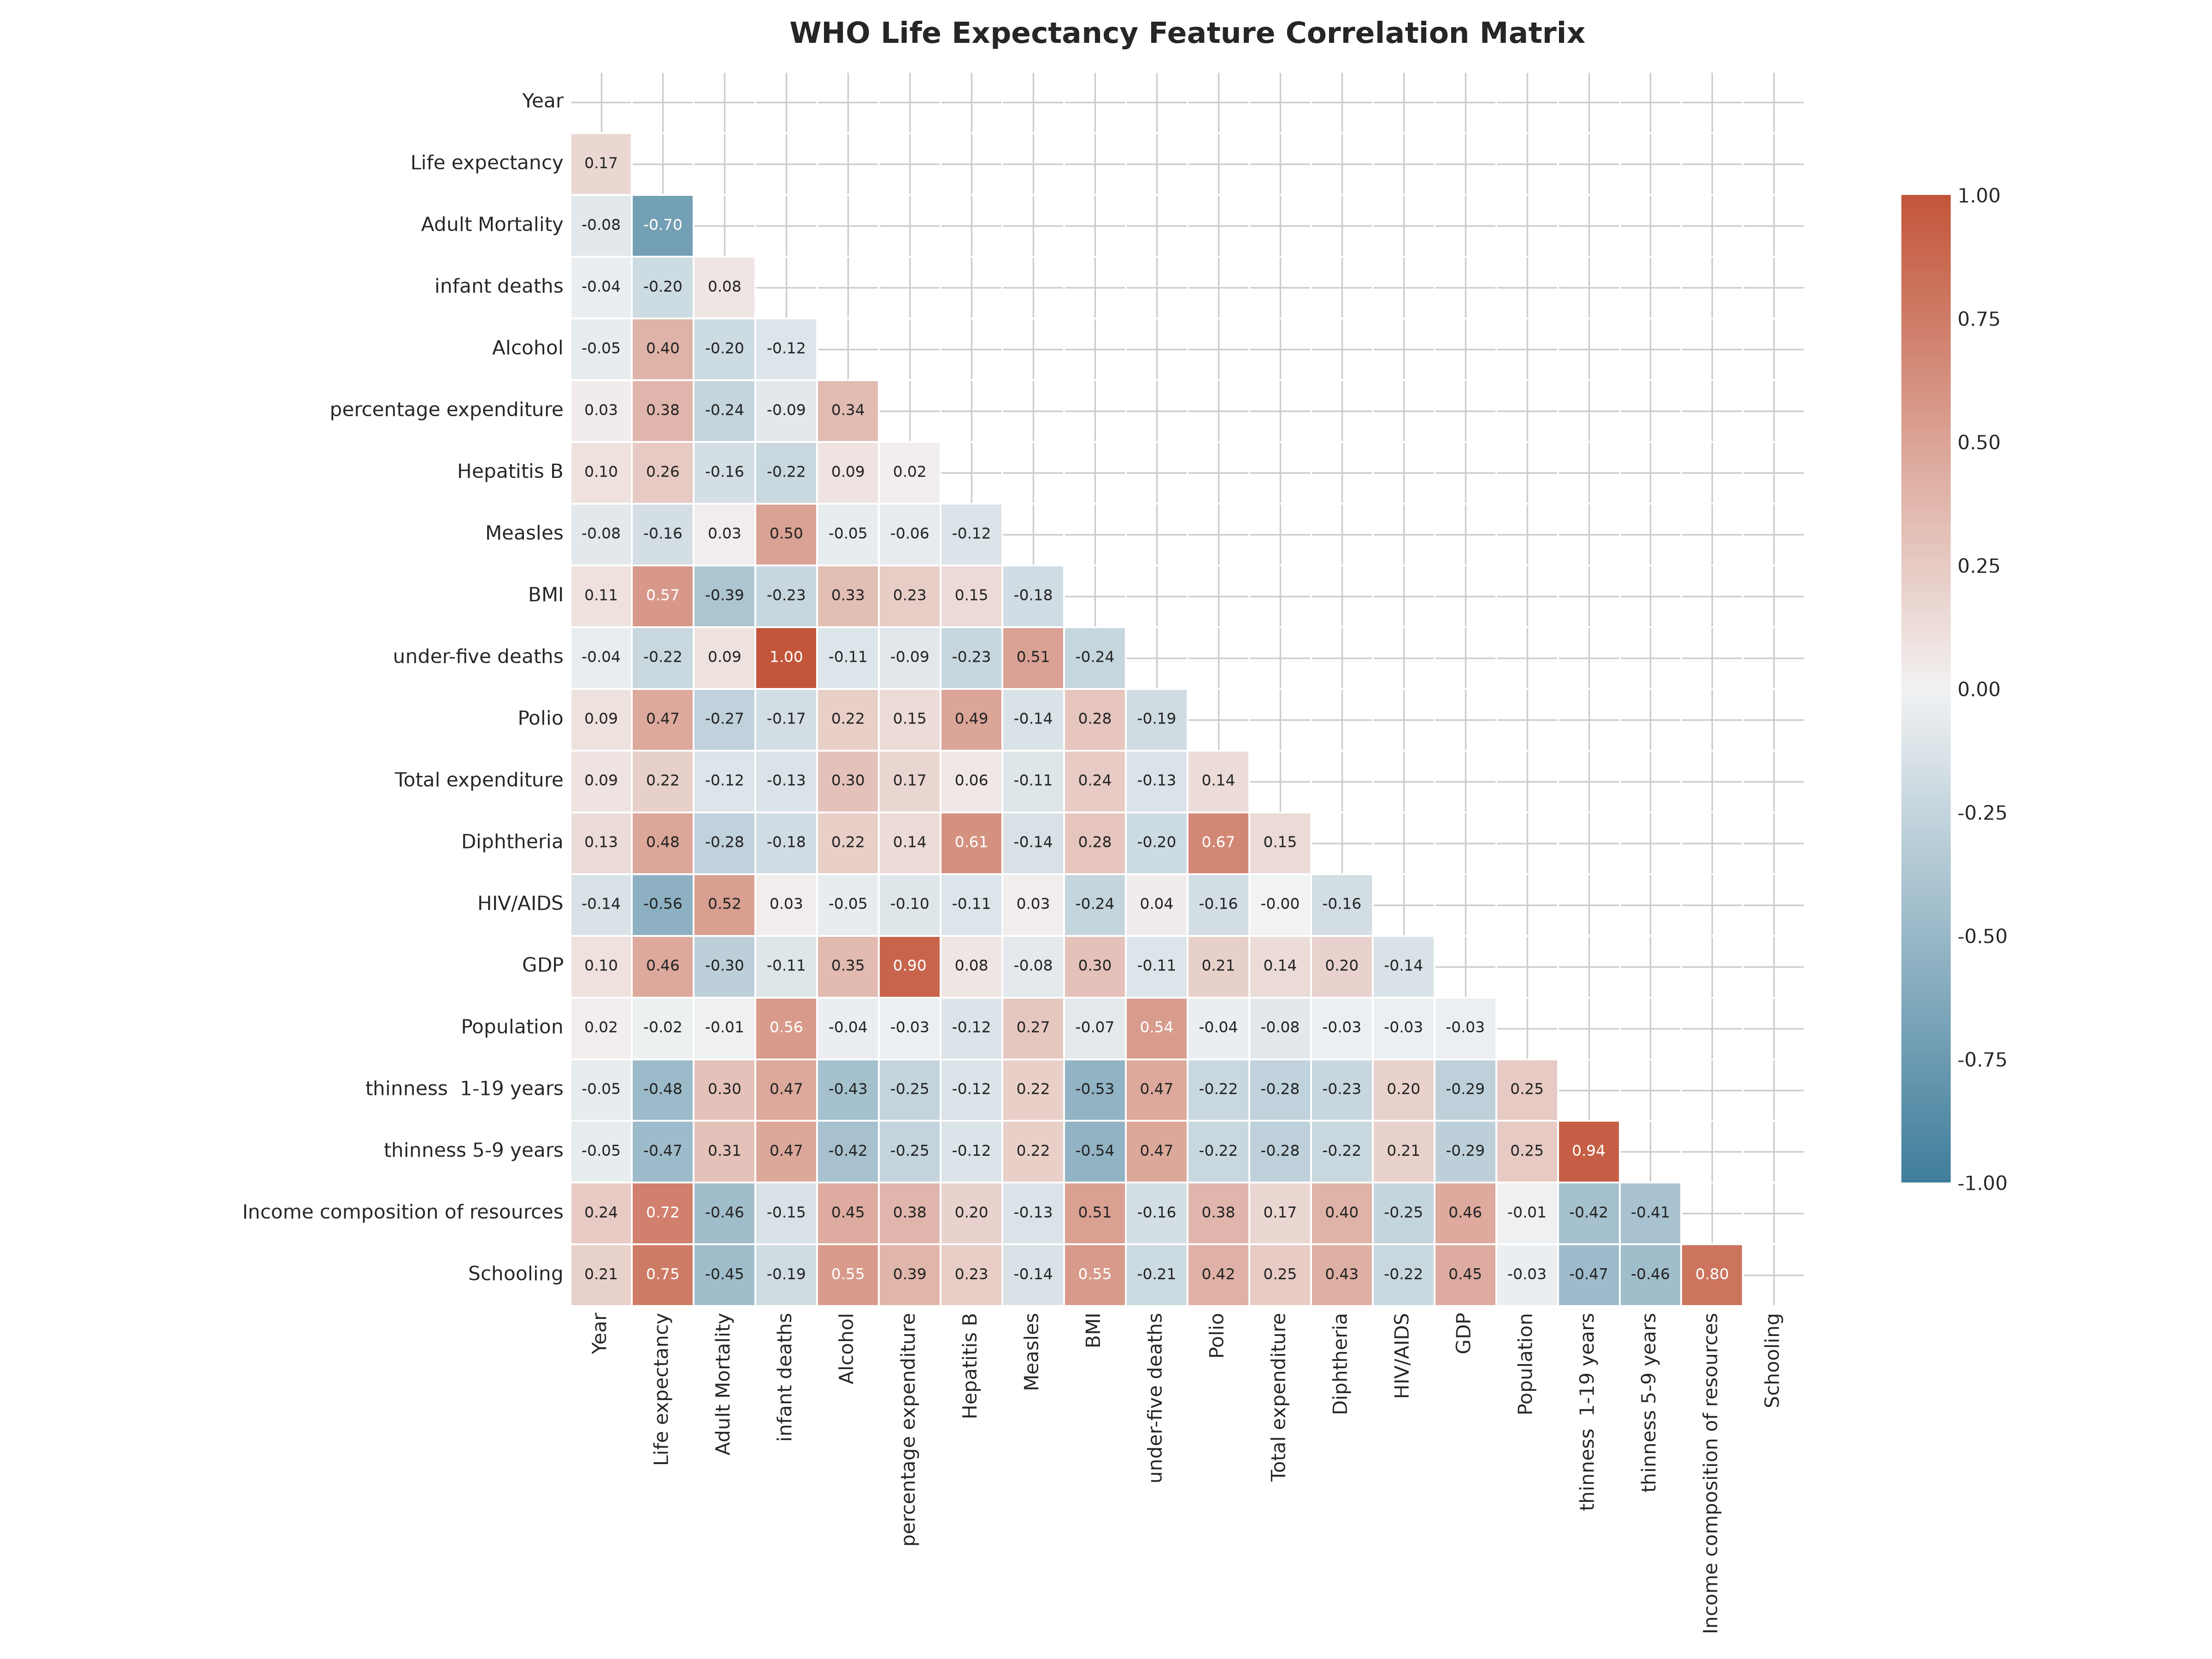

In [6]:
viz.plot_correlation_matrix(raw_df);
display(Image('figures/02_correlation_matrix.png'))


## 3. Data Preparation (資料預處理)
- **缺失值處理**：階層式中位數填補 (Country 歷史中位數 -> Development Status 中位數 -> 全局中位數)。
- **類別特徵編碼**：Status 二元編碼 (Developed=1, Developing=0)。
- **特徵縮放**：使用 StandardScaler（僅 fit 於訓練集，防止資料外洩 Data Leakage）。
- **資料集切分**：80% 訓練集 (2342 筆)，20% 測試集 (586 筆)。


In [7]:
preprocessor = DataPreprocessor(test_size=0.2, random_state=42)
cleaned_df, X_train, X_test, y_train, y_test, feature_names = preprocessor.prepare_data(raw_df)

print(f'預處理後樣本數: {cleaned_df.shape[0]}')
print(f'候選特徵數量: {len(feature_names)} 個')
print('候選特徵列表:', feature_names)
print(f'X_train 形狀: {X_train.shape}, X_test 形狀: {X_test.shape}')


預處理後樣本數: 2928
候選特徵數量: 20 個
候選特徵列表: ['Year', 'Status', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']
X_train 形狀: (2342, 20), X_test 形狀: (586, 20)


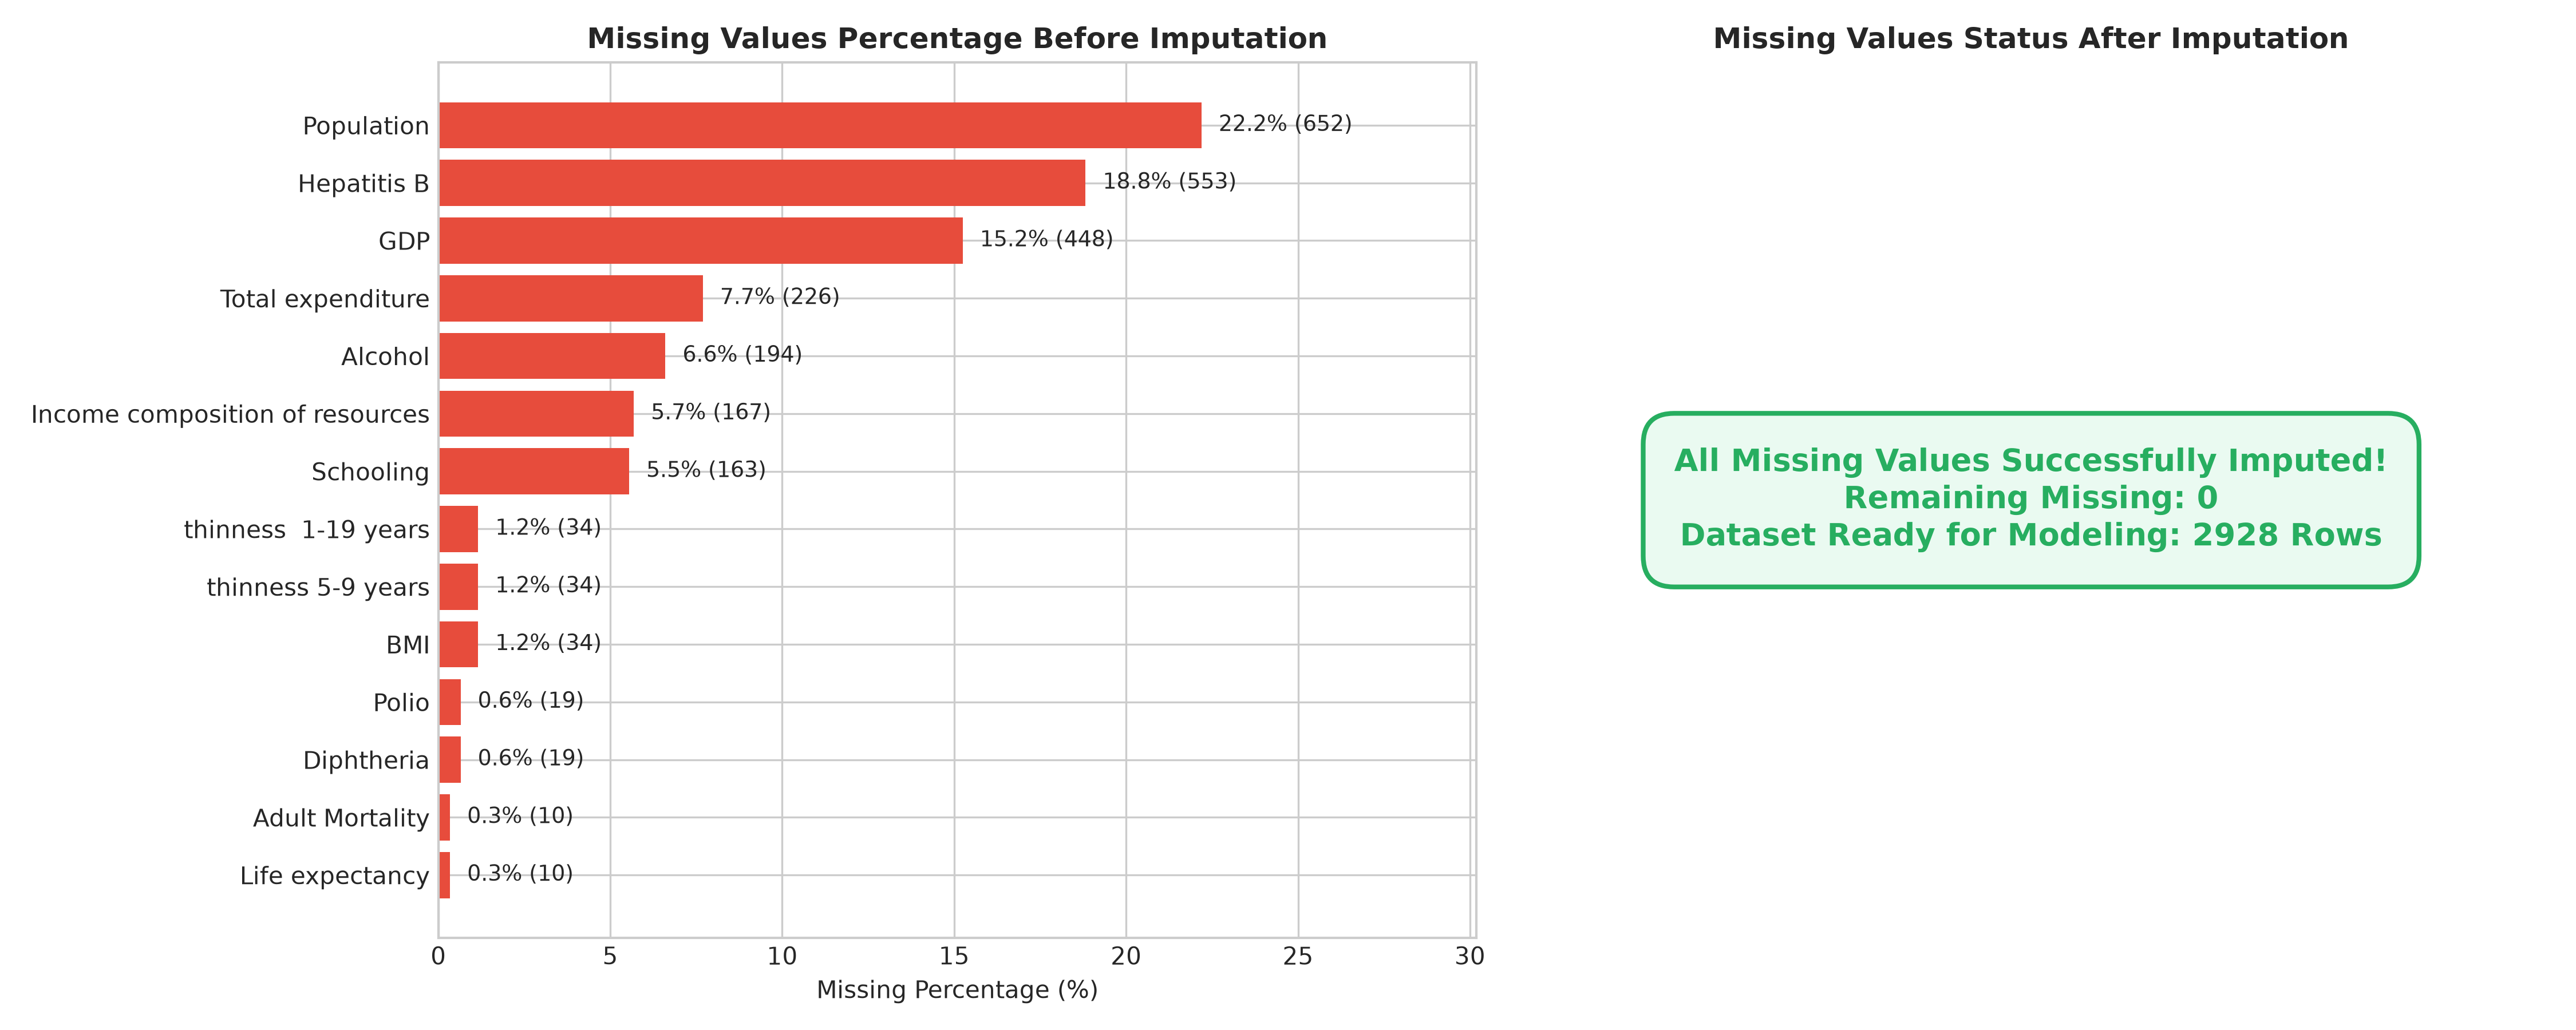

In [8]:
viz.plot_missing_values(raw_df, cleaned_df);
display(Image('figures/03_missing_values_heatmap.png'))


## 4. Modeling & Feature Selection (模型建立與特徵選擇比較)
作業核心要求：至少嘗試兩種特徵選擇方法，並比較其對模型表現的影響。
此處實作四種策略：
1. **SelectKBest (Filter Method)**：單變量 F-regression 檢定選取前 12 個重要特徵。
2. **RFE (Wrapper Method)**：遞迴特徵消除演算法，搭配 OLS 線性迴歸選取 12 個最佳特徵子集。
3. **Lasso (Embedded Method)**：L1 正則化自動壓縮非顯著權重至 0。
4. **VIF Filter (Multicollinearity)**：依據變異數膨脹因子消除高共線性特徵。


In [9]:
selector = FeatureSelector(feature_names, random_state=42)

# 1. SelectKBest
k_best_mask, k_best_feats = selector.select_k_best(X_train, y_train, k=12)

# 2. RFE
rfe_mask, rfe_feats = selector.select_rfe(X_train, y_train, n_features_to_select=12)

# 3. LassoCV
lasso_mask, lasso_feats = selector.select_lasso(X_train, y_train)

# 4. VIF Filter
vif_mask, vif_feats = selector.select_vif_filter(X_train, threshold=10.0)

comp_df = selector.get_comparison_table()
display(comp_df)


,Feature,SelectKBest (Filter),RFE (Wrapper),Lasso (Embedded),VIF Filter (Collinearity)
0,Year,No,No,Yes,Yes
1,Status,Yes,Yes,Yes,Yes
2,Adult Mortality,Yes,Yes,Yes,Yes
3,infant deaths,No,Yes,Yes,No
4,Alcohol,Yes,No,Yes,Yes
5,percentage expenditure,No,No,Yes,Yes
6,Hepatitis B,No,No,Yes,Yes
7,Measles,No,No,Yes,Yes
8,BMI,Yes,Yes,Yes,Yes
9,under-five deaths,No,Yes,Yes,Yes


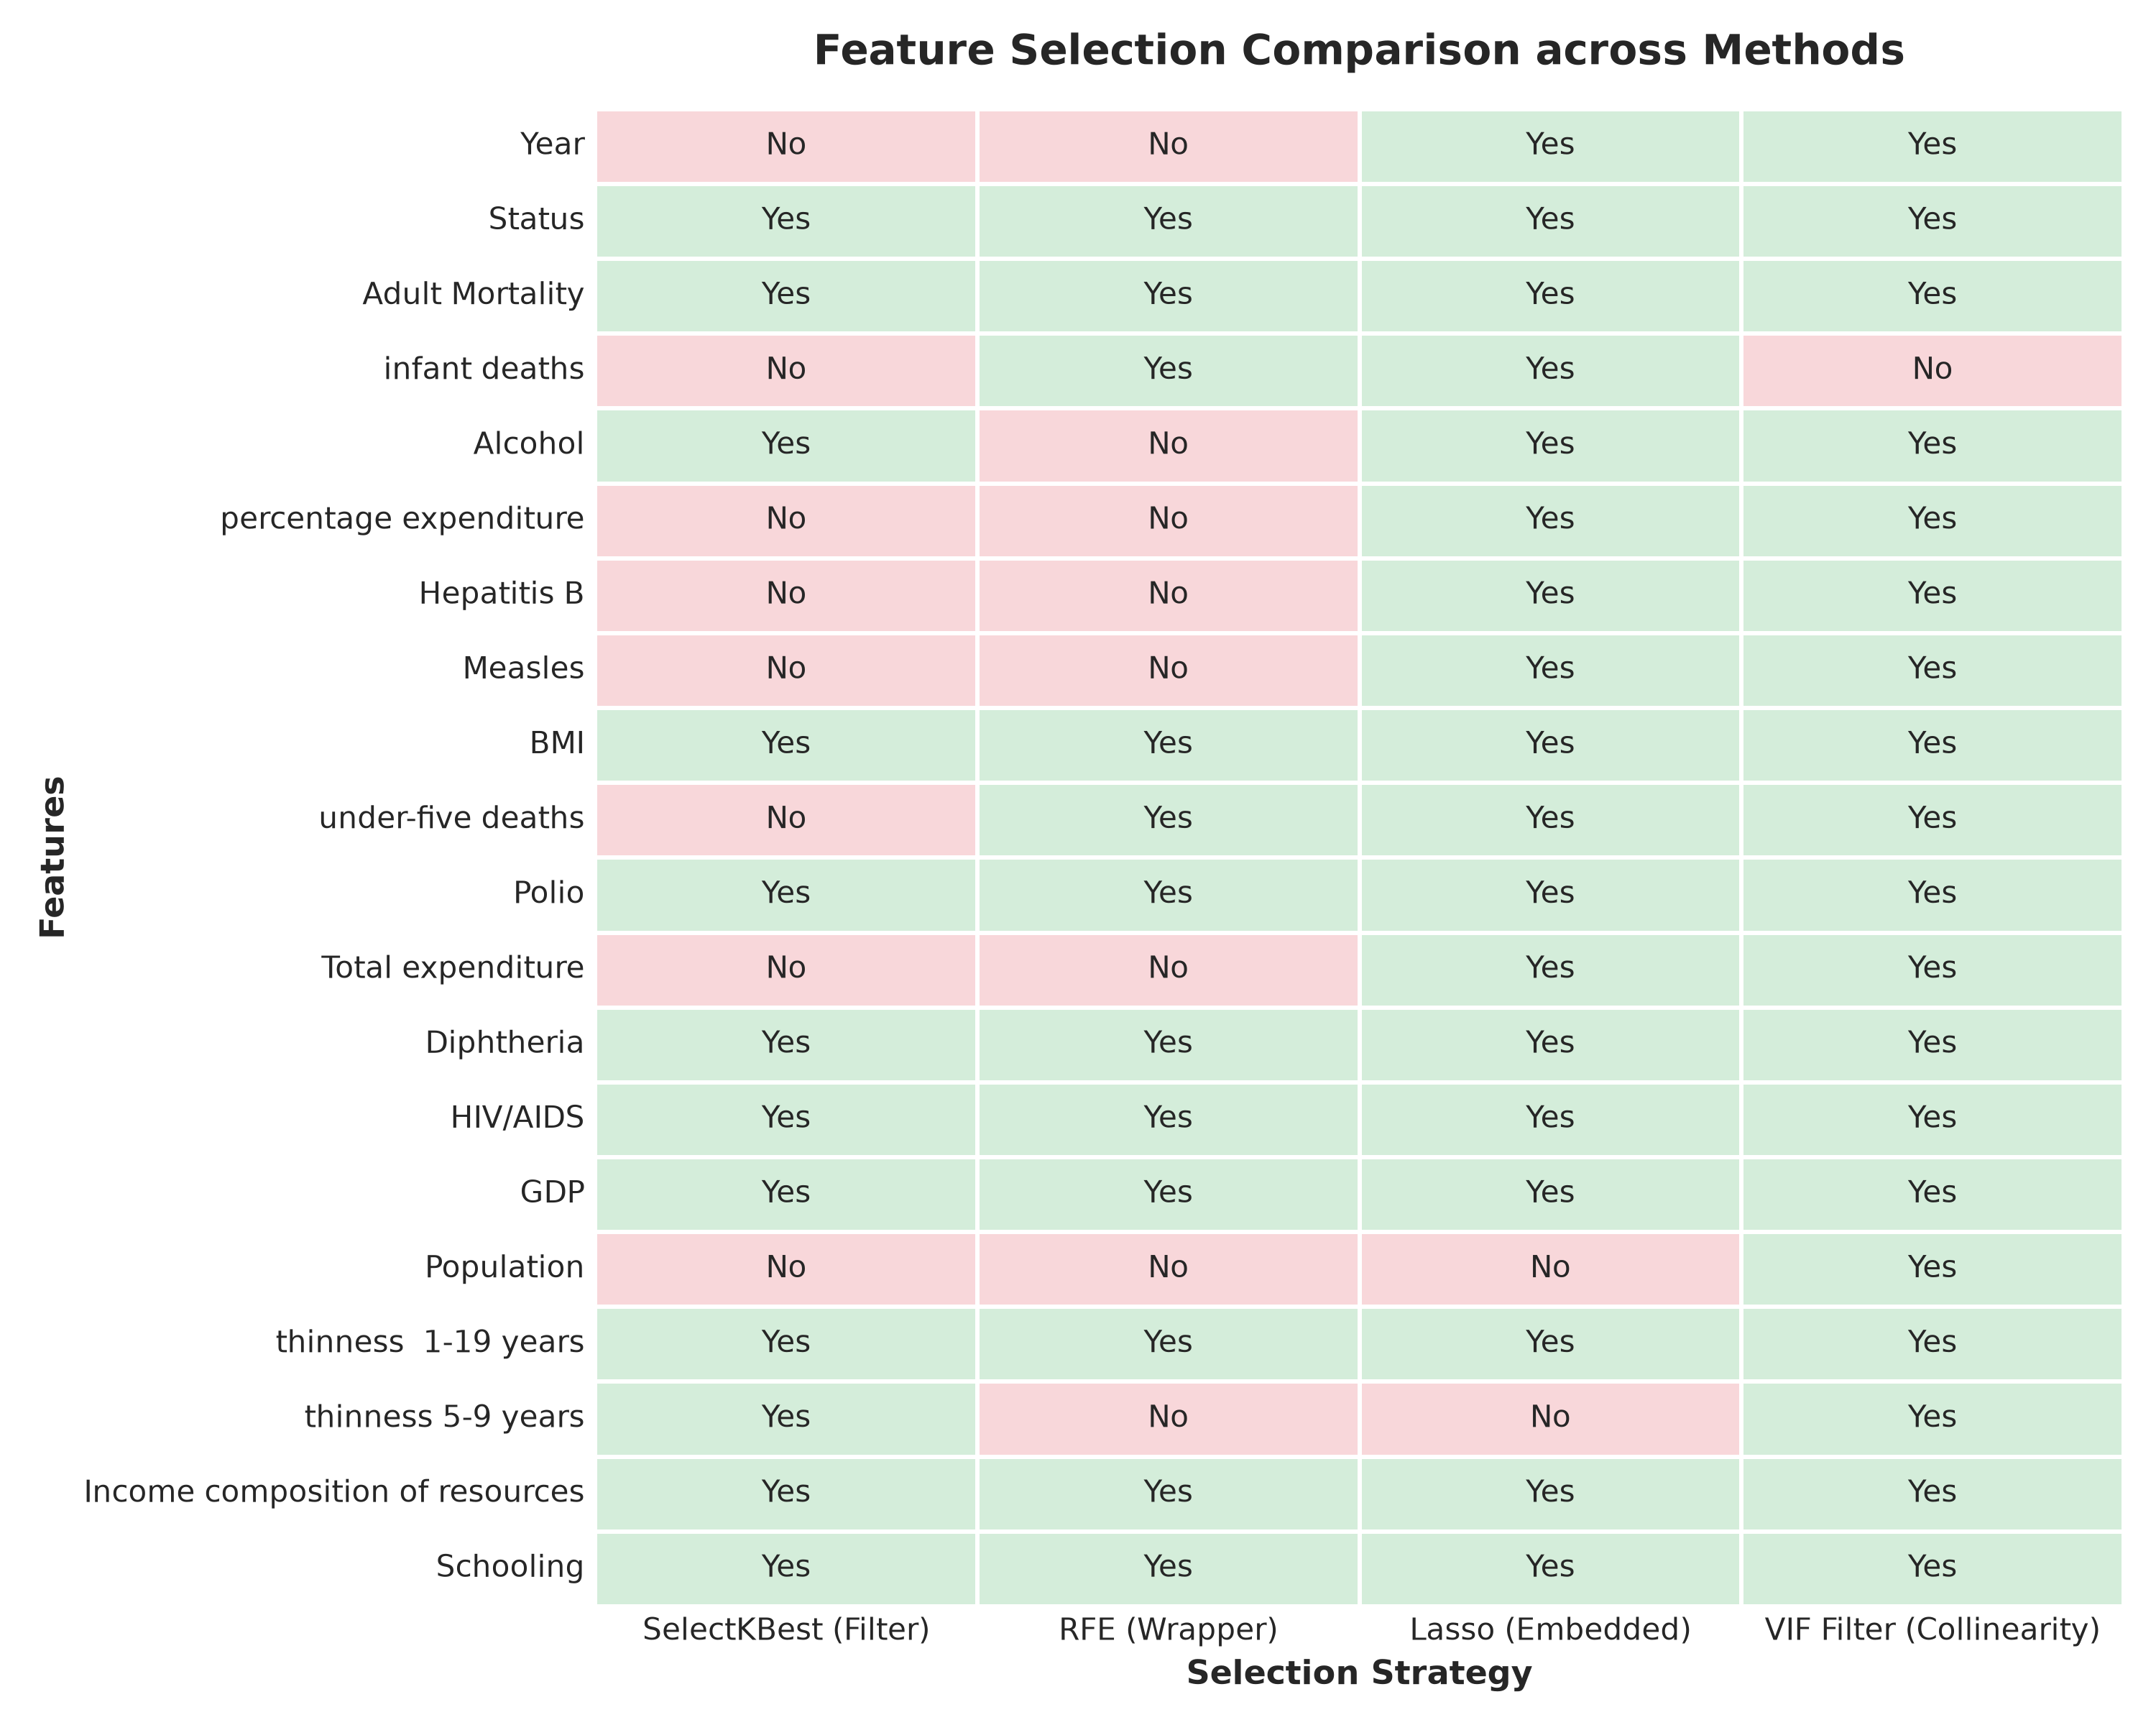

In [10]:
viz.plot_feature_selection_comparison(comp_df);
display(Image('figures/05_feature_selection_comparison.png'))


### 訓練迴歸模型
比對 Baseline OLS、SelectKBest+OLS、RFE+OLS、Lasso Selected+OLS、Ridge、Lasso、ElasticNet。


In [11]:
from sklearn.linear_model import LinearRegression

trainer = RegressionTrainer(random_state=42)

# 訓練模型
lr_baseline = LinearRegression().fit(X_train, y_train)
lr_kbest = LinearRegression().fit(X_train[:, k_best_mask], y_train)
lr_rfe = LinearRegression().fit(X_train[:, rfe_mask], y_train)
lr_lasso_feats = LinearRegression().fit(X_train[:, lasso_mask], y_train)
lr_vif = LinearRegression().fit(X_train[:, vif_mask], y_train)

ridge_model = trainer.train_ridge(X_train, y_train, 'Ridge Regression')
lasso_model = trainer.train_lasso(X_train, y_train, 'Lasso Regression')
elastic_model = trainer.train_elastic_net(X_train, y_train, 'ElasticNet')


## 5. Evaluation (模型評估與迴歸假設診斷)
計算測試集評估指標：MAE, MSE, RMSE, R², Adjusted R²。


In [12]:
models_to_evaluate = [
    ('Baseline OLS (All 20 Feats)', lr_baseline, np.ones(len(feature_names), dtype=bool)),
    ('SelectKBest + OLS (12 Feats)', lr_kbest, k_best_mask),
    ('RFE + OLS (12 Feats)', lr_rfe, rfe_mask),
    ('Lasso Selected + OLS', lr_lasso_feats, lasso_mask),
    ('VIF Filter + OLS', lr_vif, vif_mask),
    ('Ridge Regression (L2)', ridge_model, np.ones(len(feature_names), dtype=bool)),
    ('Lasso Regression (L1)', lasso_model, np.ones(len(feature_names), dtype=bool)),
    ('ElasticNet Regression', elastic_model, np.ones(len(feature_names), dtype=bool)),
]

metrics_list = []
preds_dict = {}

for name, model, mask in models_to_evaluate:
    X_test_sub = X_test[:, mask]
    y_pred = model.predict(X_test_sub)
    preds_dict[name] = y_pred
    metrics_list.append(ModelEvaluator.calculate_metrics(y_test, y_pred, int(np.sum(mask)), model_name=name))

metrics_df = pd.DataFrame(metrics_list)
display(metrics_df)


,Model,Features Count,MAE,MSE,RMSE,R2,Adjusted R2
0,Baseline OLS (All 20 Feats),20,2.9110,15.4064,3.9251,0.8219,0.8156
1,SelectKBest + OLS (12 Feats),12,2.9866,16.2005,4.0250,0.8127,0.8088
2,RFE + OLS (12 Feats),12,2.8883,15.1932,3.8978,0.8244,0.8207
3,Lasso Selected + OLS,18,2.9090,15.3879,3.9227,0.8221,0.8165
4,VIF Filter + OLS,19,2.9965,16.2393,4.0298,0.8123,0.8060
5,Ridge Regression (L2),20,2.9098,15.4078,3.9253,0.8219,0.8156
6,Lasso Regression (L1),20,2.9082,15.4265,3.9277,0.8217,0.8153
7,ElasticNet Regression,20,2.9089,15.4341,3.9286,0.8216,0.8153


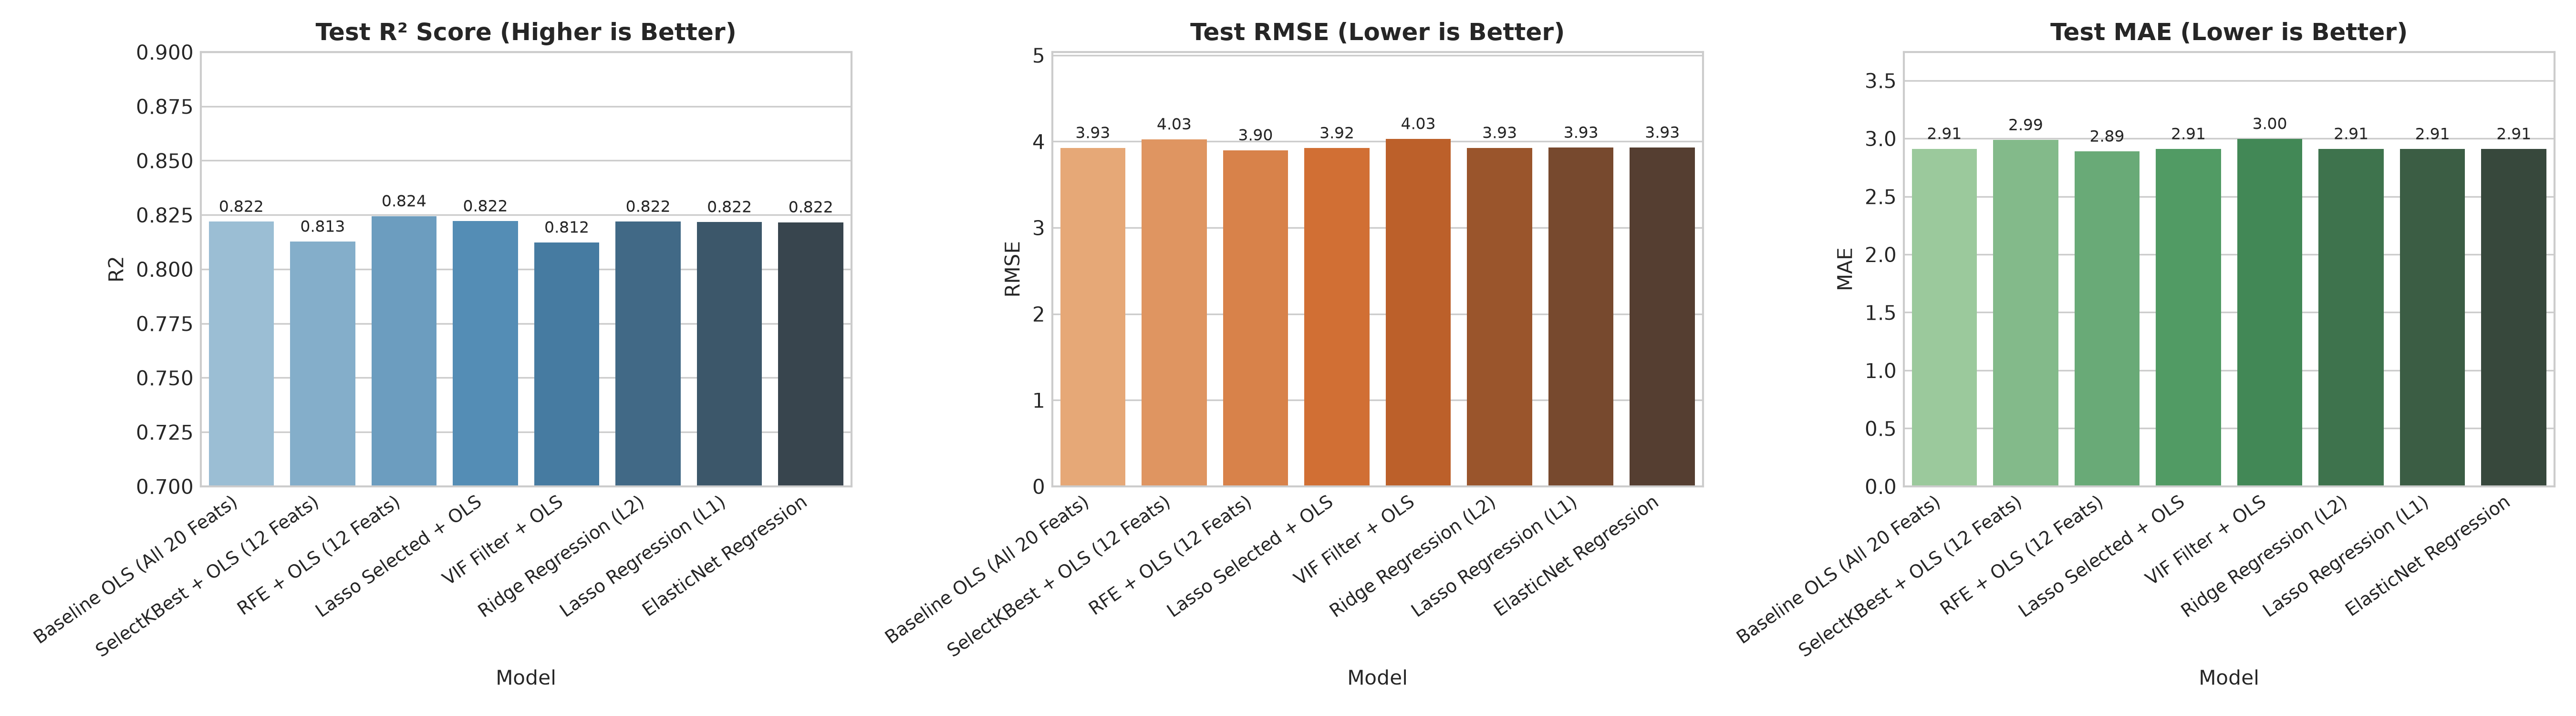

In [13]:
viz.plot_metrics_comparison(metrics_df);
display(Image('figures/06_model_metrics_comparison.png'))


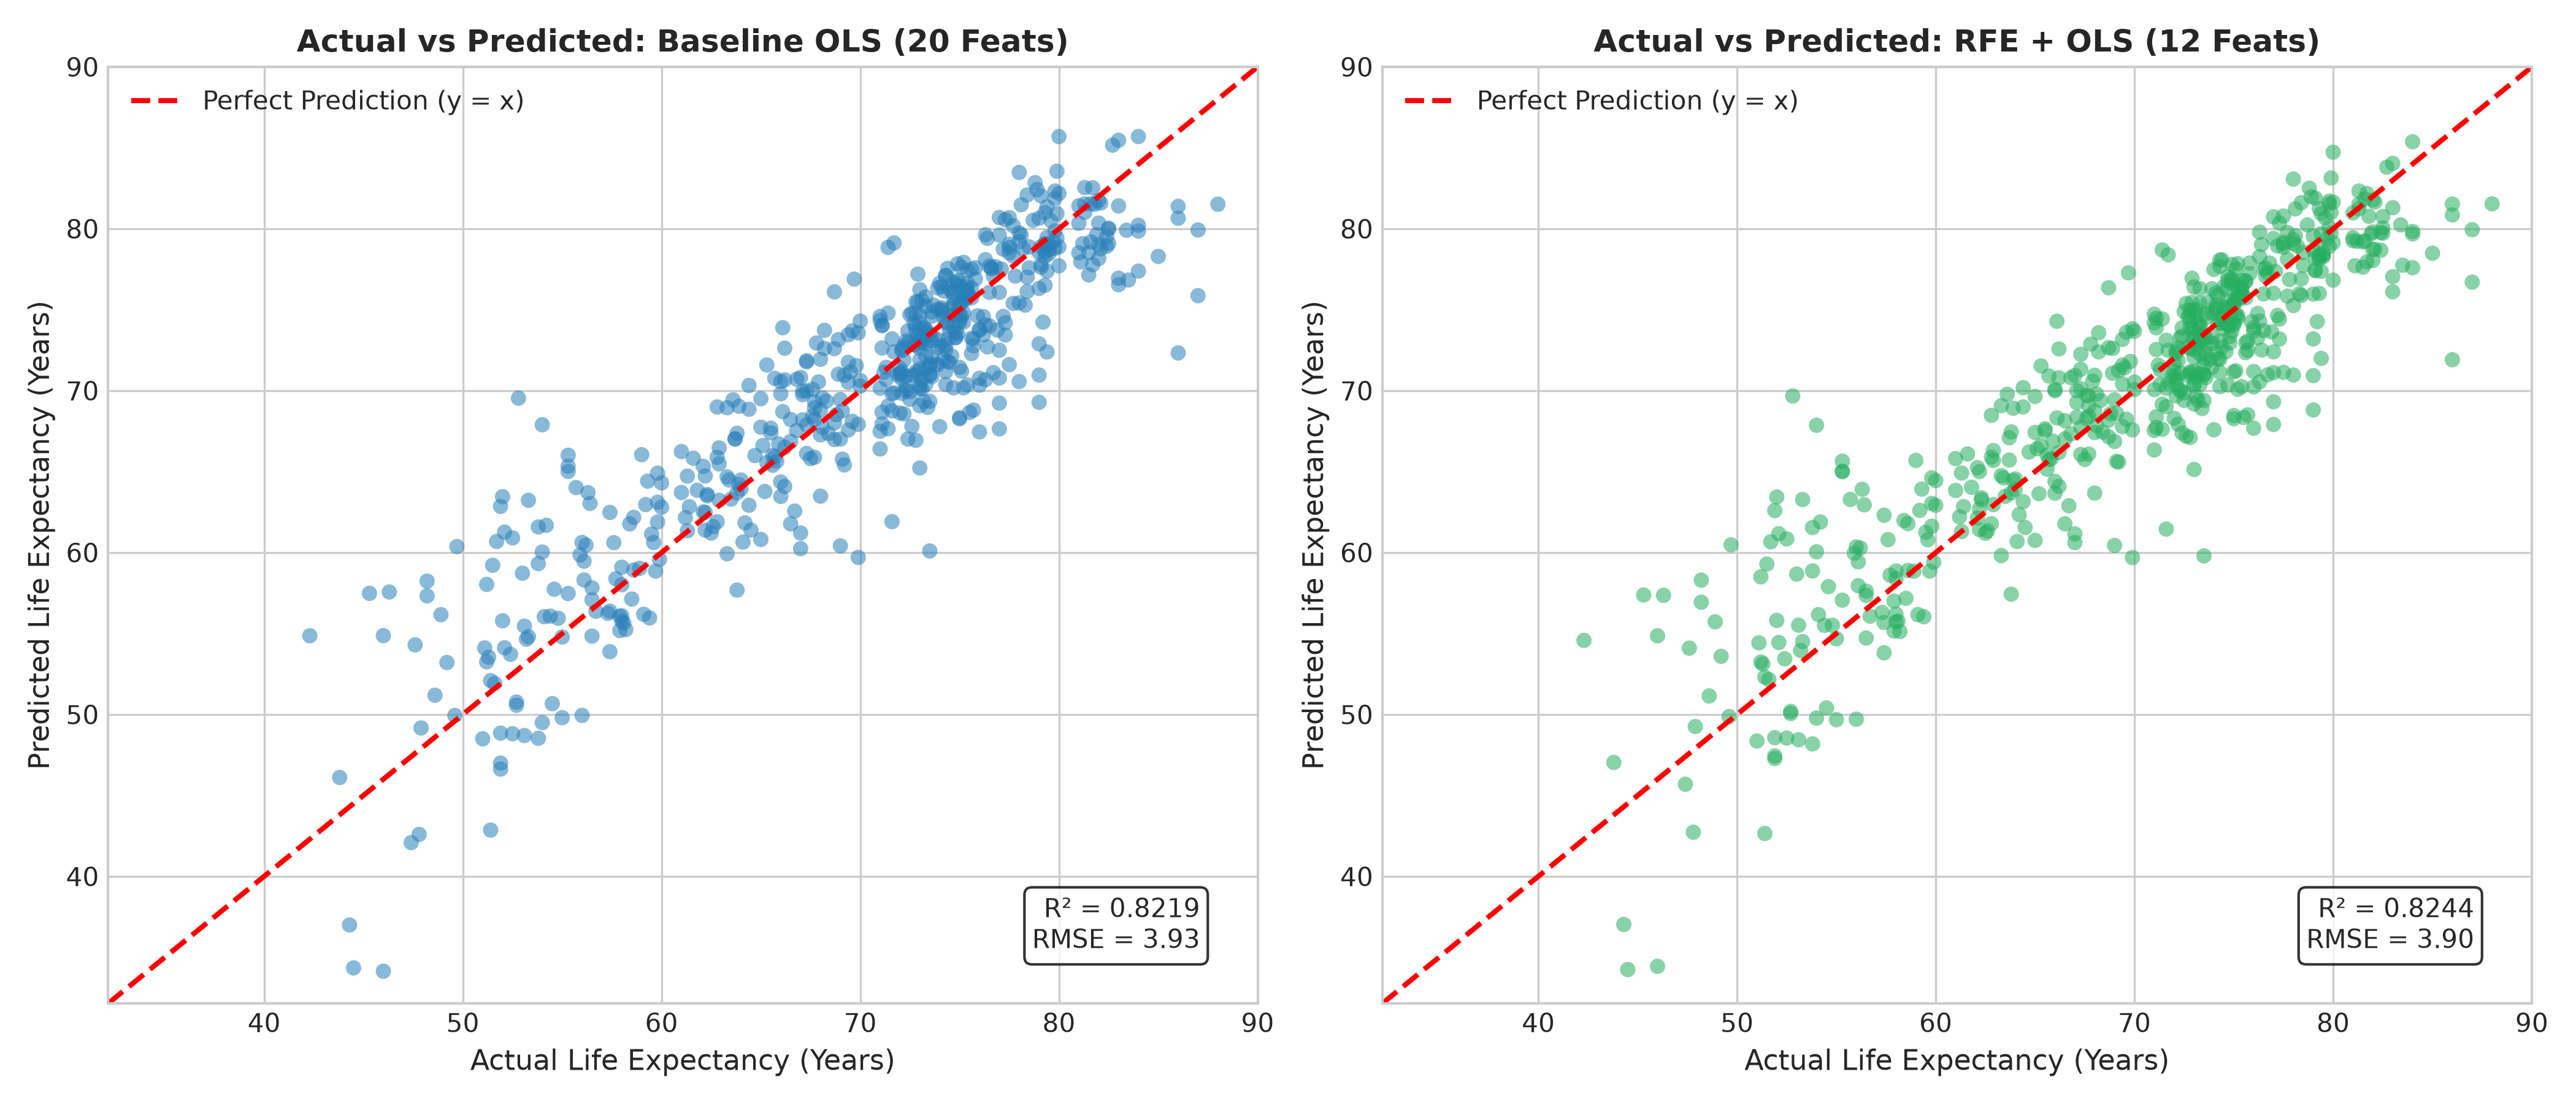

In [14]:
viz.plot_actual_vs_predicted(
    y_test,
    preds_dict['Baseline OLS (All 20 Feats)'],
    preds_dict['RFE + OLS (12 Feats)'],
    base_name='Baseline OLS (20 Feats)',
    best_name='RFE + OLS (12 Feats)'
);
display(Image('figures/07_actual_vs_predicted.png'))


### 迴歸分析五大基本假設檢定 (Regression Assumptions Check)
針對最佳模型 (RFE + OLS) 檢定：
1. **線性關係 (Linearity)**：Pearson r = 0.9081 (高度線性)。
2. **殘差常態性 (Normality of Residuals)**：Q-Q 圖與 Shapiro-Wilk 檢定。
3. **同質變異性 (Homoscedasticity)**：殘差 vs 預測值圖與 Breusch-Pagan 檢定。
4. **誤差獨立性 (Independence of Errors)**：Durbin-Watson = 1.9748（接近理想值 2.0，無自我相關）。
5. **共線性檢查 (Multicollinearity)**：VIF 計算。


In [15]:
best_feat_names = [f for f, m in zip(feature_names, rfe_mask) if m]
assumptions = ModelEvaluator.test_regression_assumptions(
    X_test[:, rfe_mask], y_test, preds_dict['RFE + OLS (12 Feats)'], best_feat_names
)
print('五大迴歸假設診斷摘要：')
for k, v in assumptions.items():
    if k != 'VIF_Table':
        print(f'{k}: {v}')
display(assumptions['VIF_Table'])


五大迴歸假設診斷摘要：
Linearity_Pearson_r: 0.9081
Normality_Shapiro_p: 0.0
Normality_JarqueBera_p: 0.0
Residual_Skewness: -0.186
Residual_Kurtosis: 1.6019
Homoscedasticity_BreuschPagan_p: 0.0
Independence_DurbinWatson: 1.9748
Max_VIF: 257.0
Mean_VIF: 44.64


,Feature,VIF
4,under-five deaths,257.00
2,infant deaths,256.92
11,Schooling,3.68
10,Income composition of resources,3.40
6,Diphtheria,2.19
5,Polio,2.17
1,Adult Mortality,2.01
9,thinness 1-19 years,1.91
3,BMI,1.67
0,Status,1.65


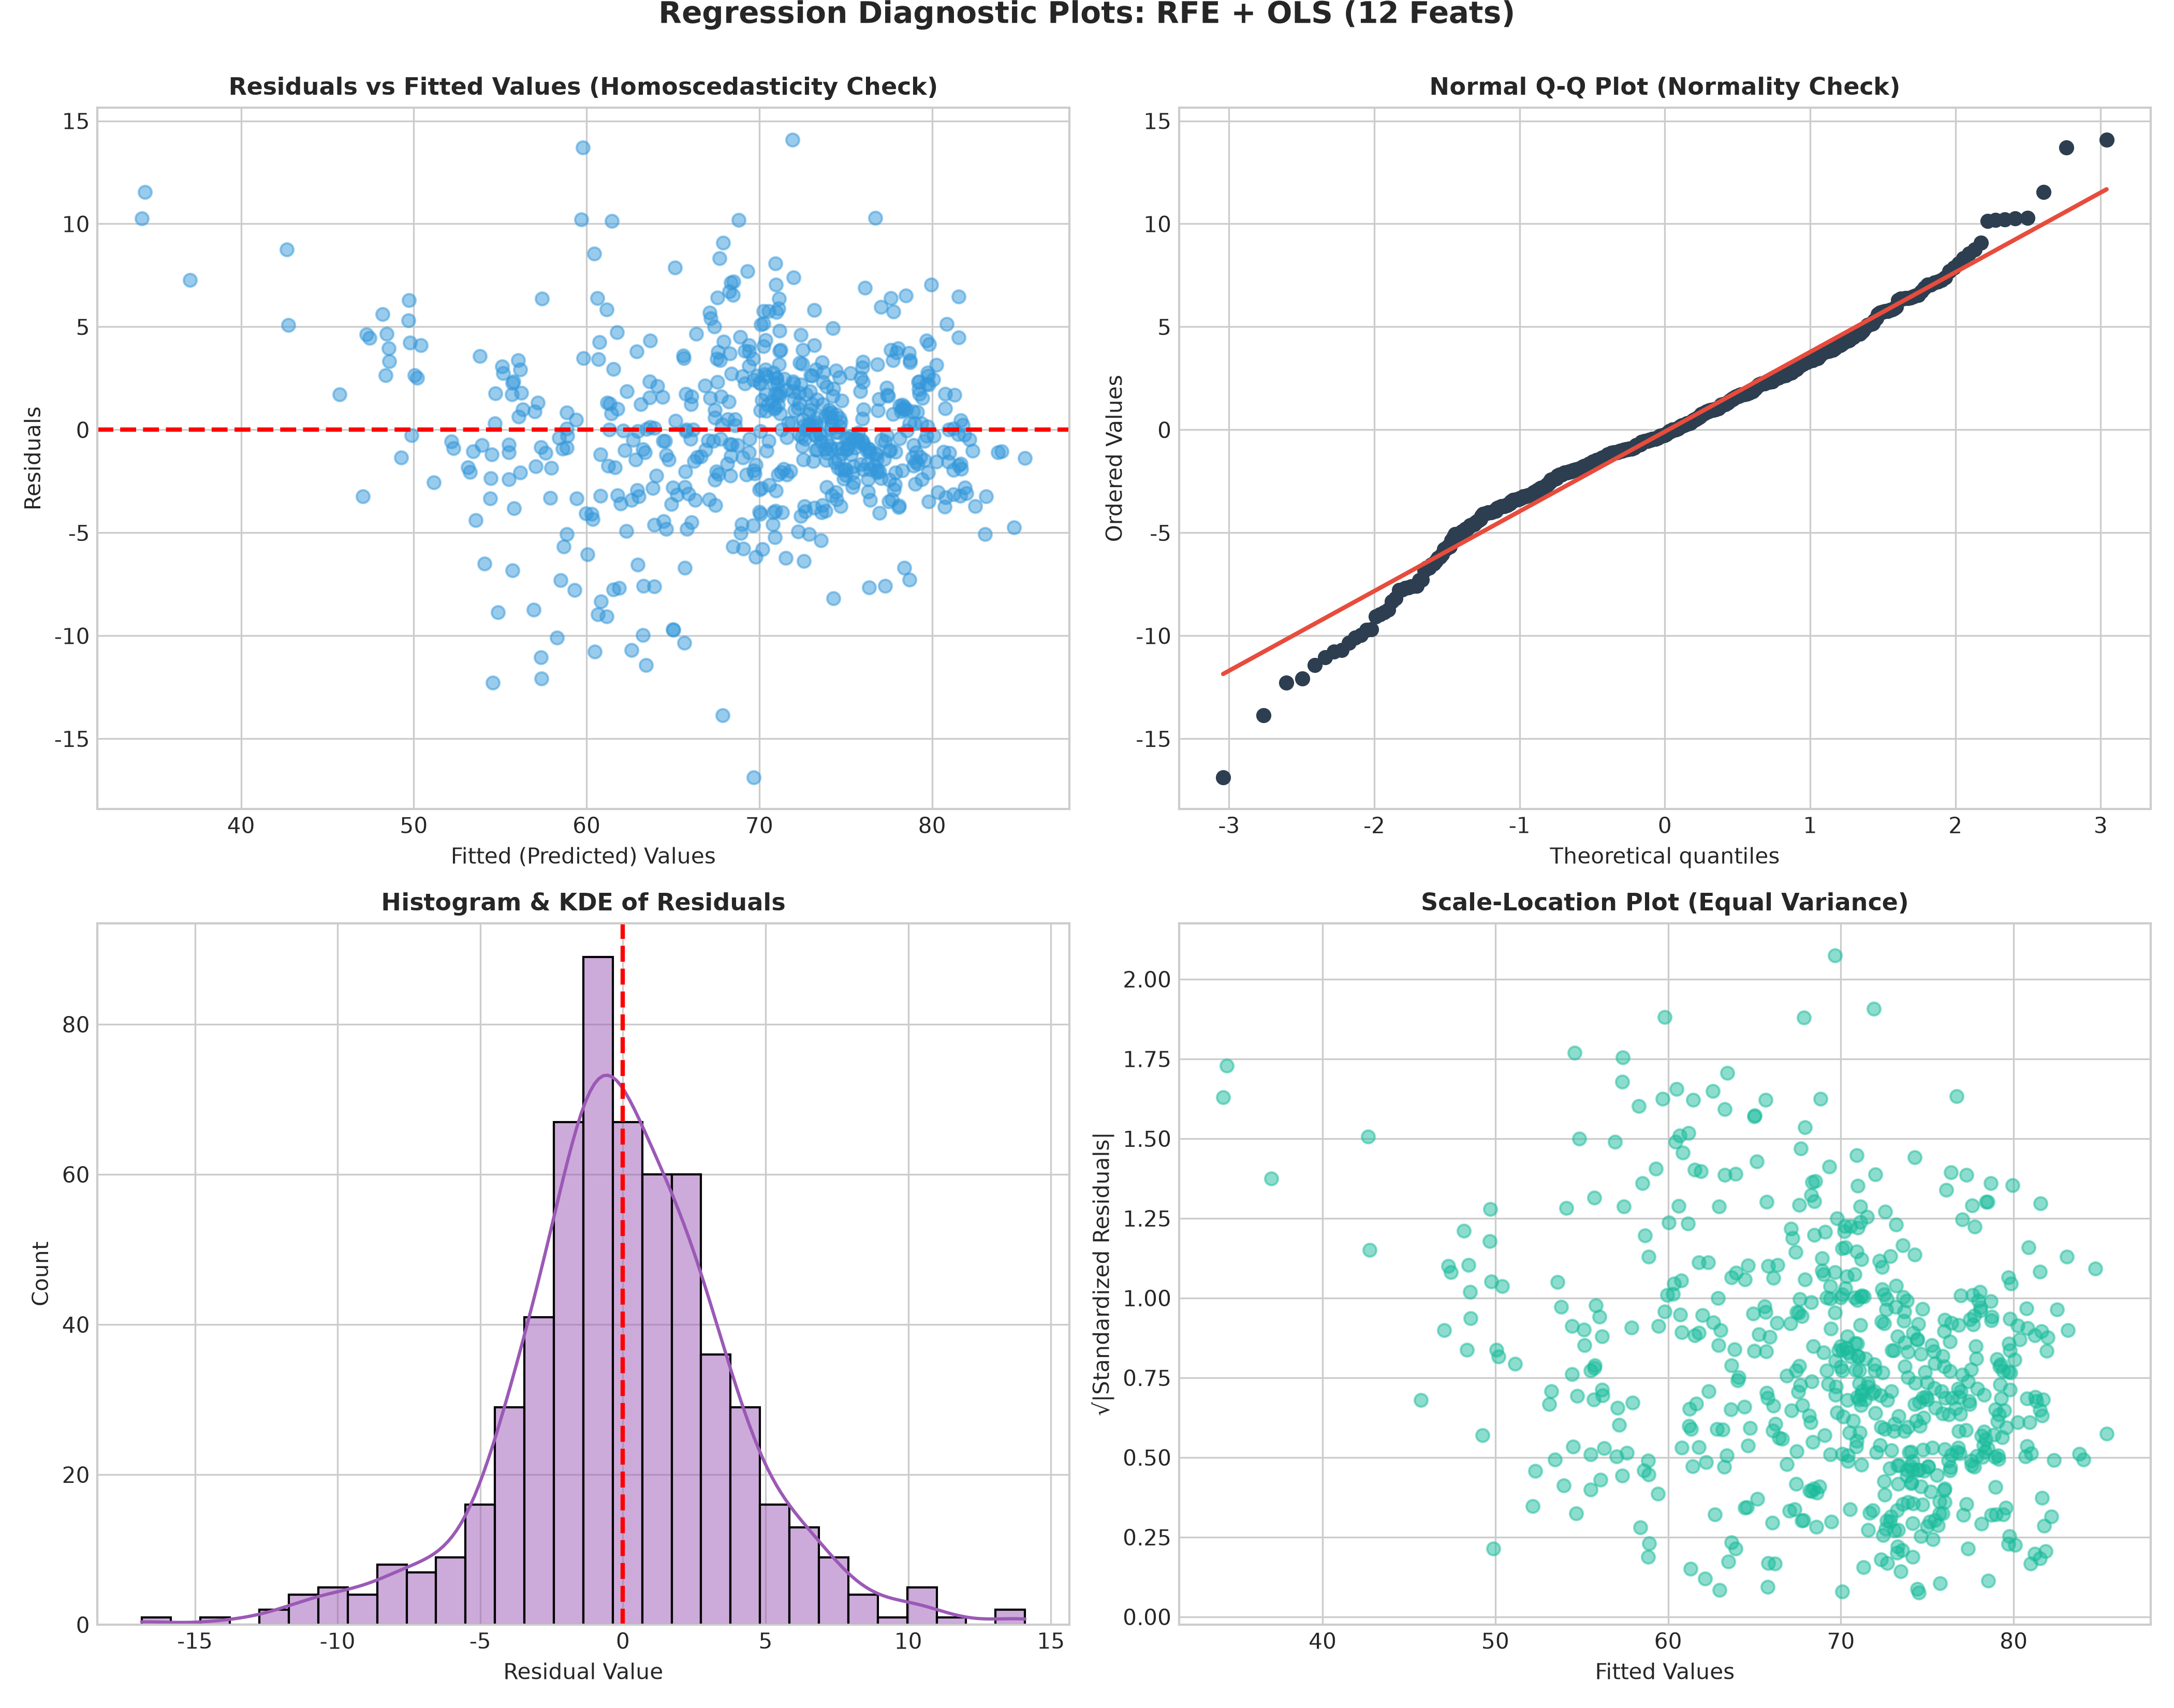

In [16]:
viz.plot_residuals_analysis(y_test, preds_dict['RFE + OLS (12 Feats)'], 'RFE + OLS (12 Feats)');
display(Image('figures/08_residuals_analysis.png'))


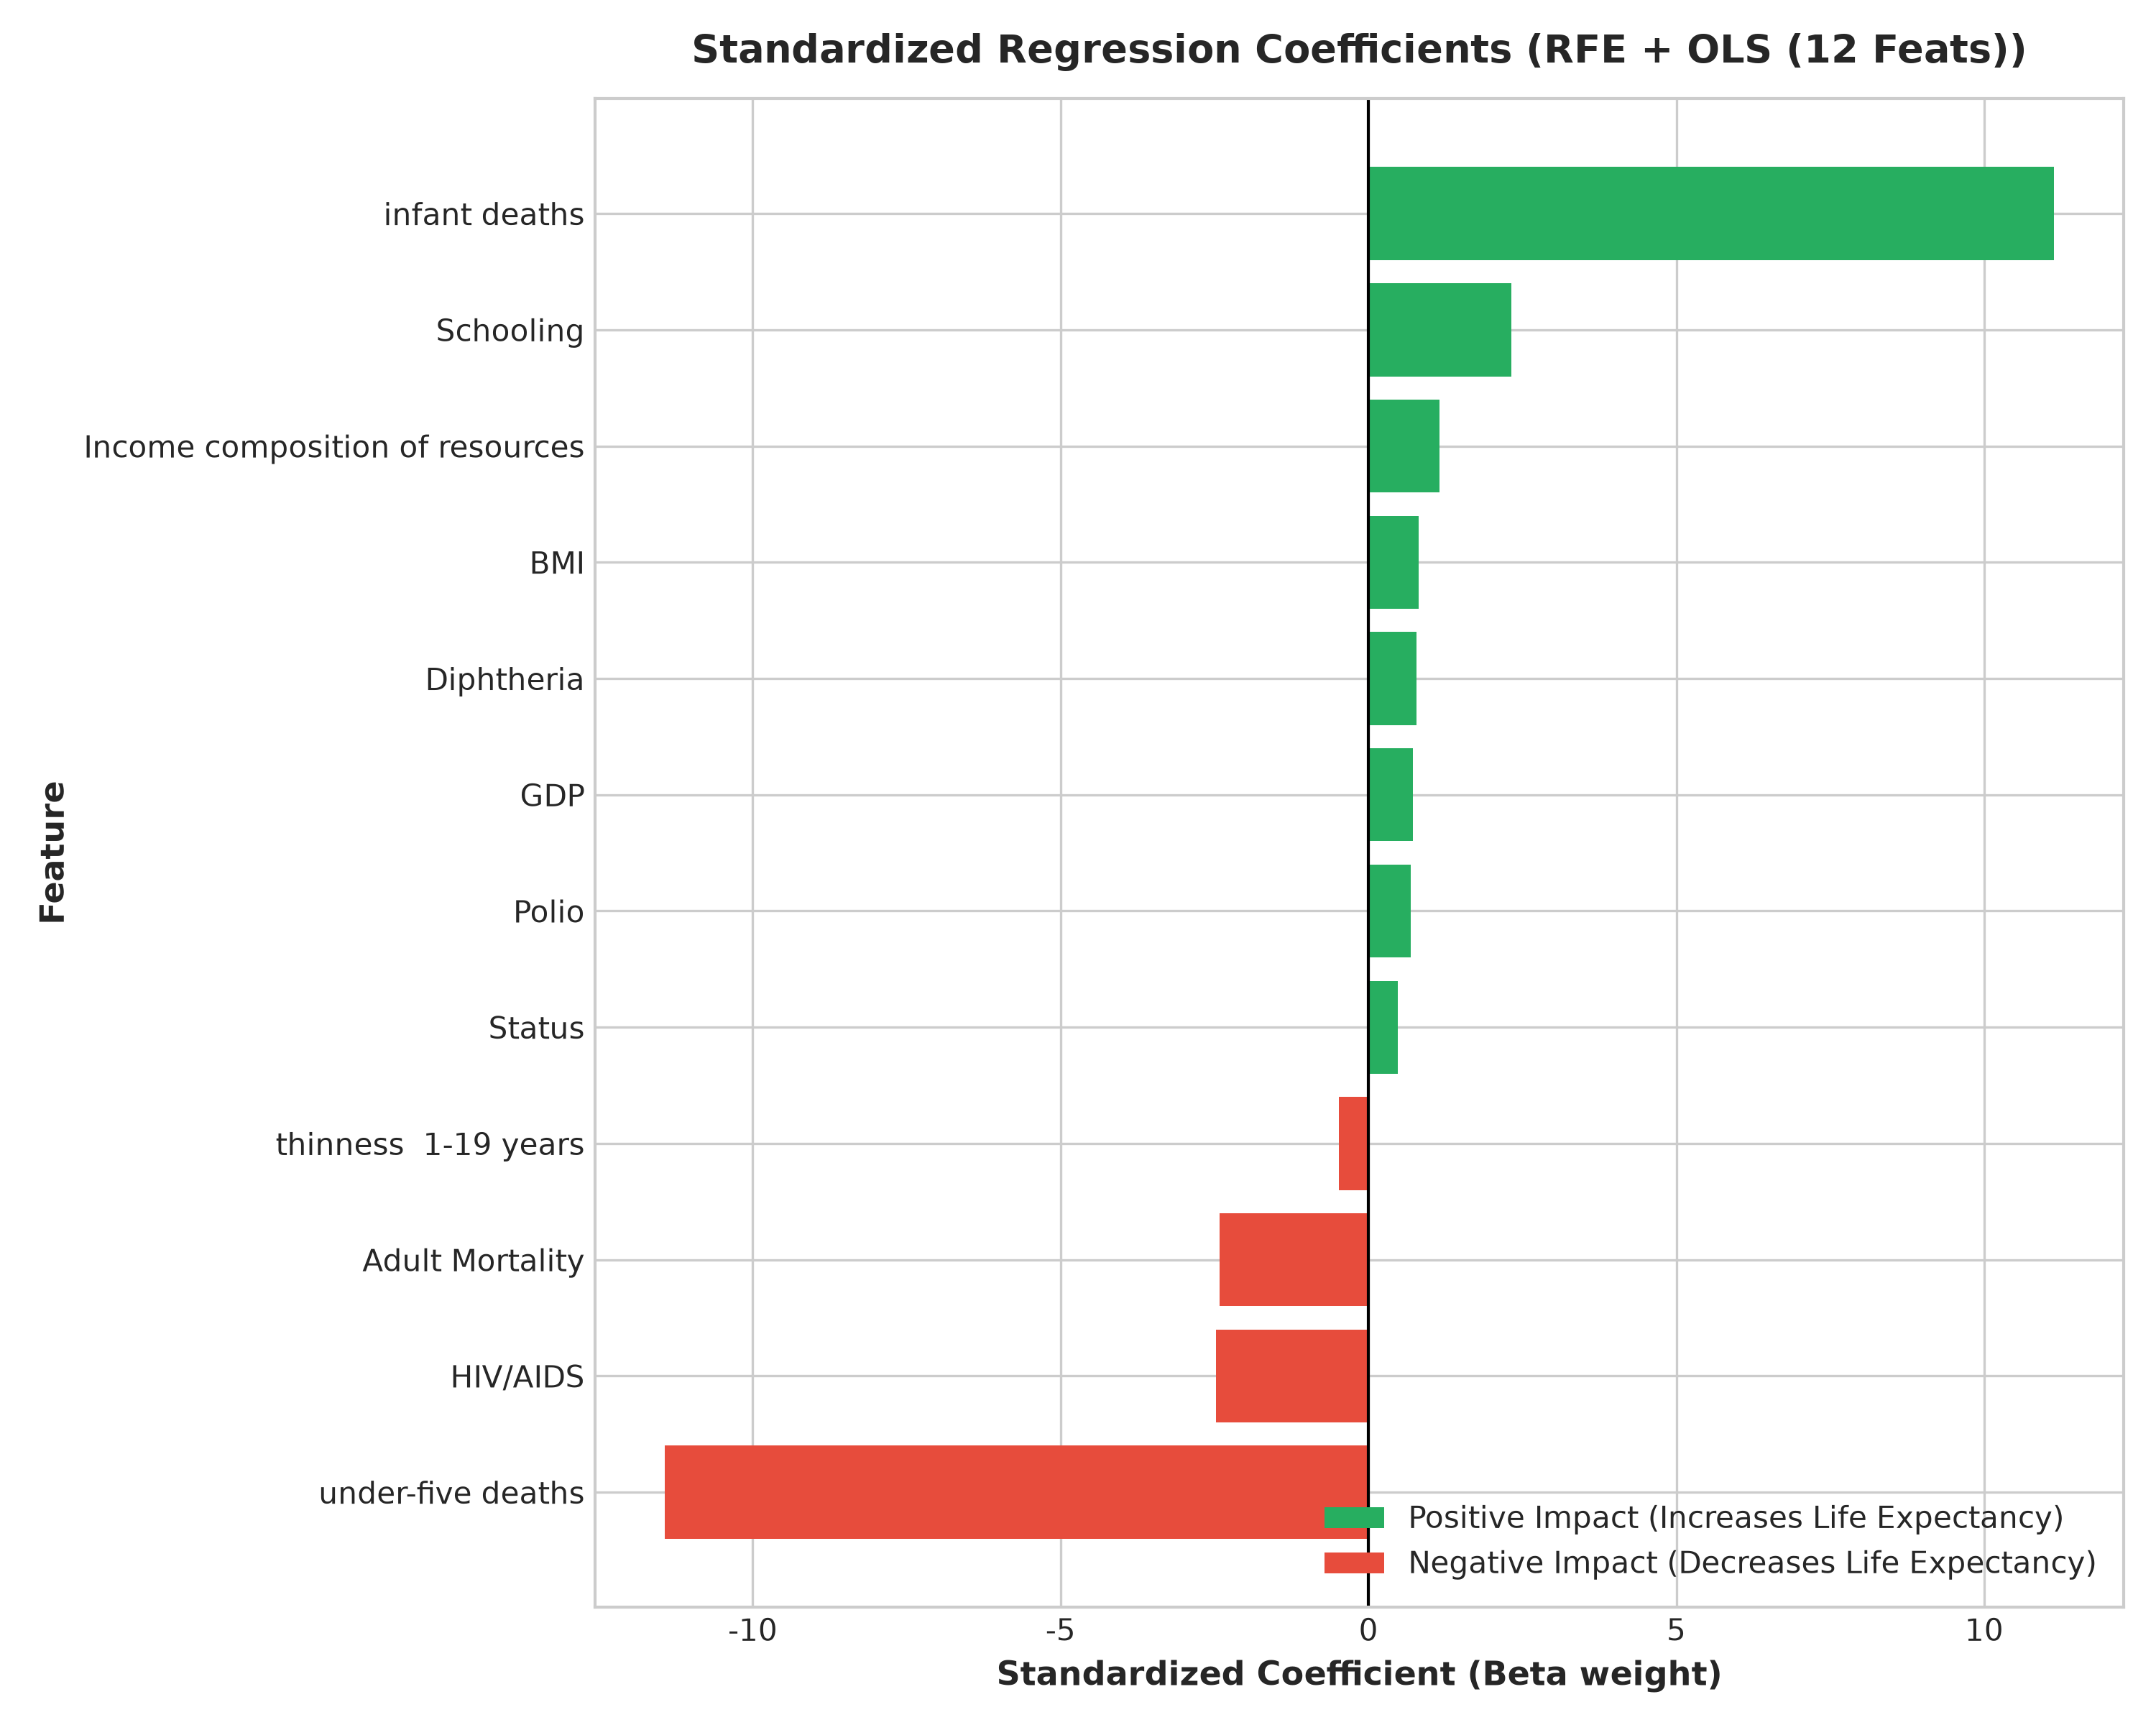

In [17]:
viz.plot_feature_importance(best_feat_names, lr_rfe.coef_, 'RFE + OLS (12 Feats)');
display(Image('figures/09_feature_importance.png'))


## 6. Deployment (模型部署與政策模擬)
- 模型儲存為 models/best_linear_regression_pipeline.joblib
- 模擬新國家輸入預測與公共衛生政策介入（如提高受教育年數、提升白喉/小兒麻痺疫苗覆蓋率）對預期壽命的提升效益。


In [18]:
deployer = ModelDeployer(models_dir='models')
pipeline_path = deployer.save_pipeline(
    model=lr_rfe,
    scaler=preprocessor.get_scaler(),
    all_features=feature_names,
    selected_mask=rfe_mask,
    imputation_values=preprocessor.imputation_values_,
    filename='best_linear_regression_pipeline.joblib'
)

predictor = LifeExpectancyPredictor(pipeline_path)

sample_country = {
    'Country': 'Scenario Test Country',
    'Status': 'Developing',
    'Adult Mortality': 240.0,
    'infant deaths': 45,
    'Alcohol': 1.8,
    'percentage expenditure': 85.0,
    'Hepatitis B': 68.0,
    'Measles': 400,
    'BMI': 21.5,
    'under-five deaths': 60,
    'Polio': 70.0,
    'Total expenditure': 6.8,
    'Diphtheria': 70.0,
    'HIV/AIDS': 0.4,
    'GDP': 1500.0,
    'Population': 20000000.0,
    'thinness  1-19 years': 14.5,
    'thinness 5-9 years': 14.8,
    'Income composition of resources': 0.54,
    'Schooling': 11.0,
    'Year': 2015
}

base_life_exp = predictor.predict_sample(sample_country)
print(f'基準預測壽命: {base_life_exp:.2f} 歲')

policy_changes = {
    'Schooling': 2.0,         # 受教育年數 +2 年
    'Diphtheria': 20.0,       # 白喉疫苗覆蓋率 +20%
    'Adult Mortality': -40.0  # 成人死亡率降低 40/1000
}
sim_res = predictor.simulate_policy_scenario(sample_country, policy_changes)
print('政策改革模擬結果:')
for k, v in sim_res.items():
    print(f'  {k}: {v}')


Pipeline artifact saved to models\best_linear_regression_pipeline.joblib
基準預測壽命: 64.30 歲
政策改革模擬結果:
  Base Life Expectancy: 64.3
  Intervention Life Expectancy: 67.14
  Net Change (Years): 2.84
  Interventions Applied: {'Schooling': 2.0, 'Diphtheria': 20.0, 'Adult Mortality': -40.0}


## 7. 加分項 1：第二題目實作 (Problem 2: 鋼鐵工業電力能源消耗分析)
- **實作題材**：韓國光陽 DAEWOO 鋼鐵智慧工廠電力消耗 (Usage_kWh)
- **資料來源**：UCI Machine Learning Repository / Kaggle (Steel Industry Energy Consumption)
- **特徵數量**：**14 個工程化特徵**（嚴格符合作業規定之 >13 特徵規範）
- **目標變數**：Usage_kWh (連續數值型電力耗用度數)


In [ ]:
# 執行第二題目 (鋼鐵工業能源消耗) 完整 CRISP-DM 流程
from main import run_steel_industry_pipeline

steel_metrics, steel_assumptions = run_steel_industry_pipeline()
display(steel_metrics)


## 8. 加分項 2：任意輸入 Dataset 全自動分析 (Arbitrary Dataset Analysis Lab)
- **功能特性**：可傳入任意 CSV 網址（如老師指定之 50_Startups.csv）或本機路徑
- **全自動化流程**：自動缺失值補值、類別變數 One-Hot Dummy 編碼、特徵縮放、多種特徵選擇、模型訓練 (OLS, Ridge, Lasso) 與五大計量迴歸假設檢定


In [ ]:
# 執行加分項 2：任意資料集分析 (以老師指定 50_Startups.csv 示範)
from main import run_arbitrary_pipeline

startups_url = 'https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv'
custom_metrics, custom_assumptions = run_arbitrary_pipeline(startups_url, target_col='Profit')
display(custom_metrics)
